[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/QFL_DPPrivacyCatsDogs_Rofougaran2023.ipynb)

# Federated quantum learning with differential privacy for Cats vs Dogs: Rofougaran et al. (2023) step by step

**Paper.** Rod Rofougaran, Shinjae Yoo, Huan-Hsin Tseng and Samuel Yen-Chi Chen, *Federated Quantum Machine Learning with Differential Privacy*, arXiv:2310.06973 (2023), https://arxiv.org/abs/2310.06973 (a short conference paper from Cornell, Brookhaven National Laboratory and Wells Fargo).

**What the notebook does.** Many clients each hold a small private piece of the *Cats vs Dogs* photo data. A hybrid quantum-classical classifier (a frozen pre-trained VGG16 turns each photo into 512 numbers, a 512-to-4 layer feeds a 4-qubit variational circuit, the two Pauli-Z expectation values are the class scores) is trained by *federated averaging*: in every round a few clients train a copy of the global model on their own data and the server only averages the returned parameters. Each client trains with *differentially private SGD* (per-sample gradient clipping plus Gaussian noise), and a privacy accountant turns the noise level and the number of steps into an (epsilon, delta) guarantee. The notebook reproduces the two experiments of the paper (accuracy for 1, 2 and 4 local epochs with and without DP, and accuracy for three noise levels), adds accuracy-versus-epsilon and accuracy-versus-number-of-clients studies, and trains a classical model with exactly the same federated + DP mechanism on exactly the same inputs.

**How to run it.** Open it in Google Colab, keep the normal CPU runtime and choose Runtime, then Run all. No GPU, no IBM account and no token are needed (the data set is public). The first run downloads two parquet files of about 330 MB and 390 MB from Hugging Face, keeps only a seeded subset, and deletes the big files again. With `FAST_MODE = True` (the default in the configuration cell) the notebook is a small class demonstration; with `FAST_MODE = False` it uses the larger budgets listed in the configuration cell and took about two hours on a heavily shared single CPU thread in our test run (about half an hour of that is the VGG16 feature extraction; with an idle machine expect roughly an hour).

**What you will get at the end.** Photos and 2-D maps of the real data labelled cat or dog, the drawn 4-qubit circuit (PennyLane) with an assertion that the fast simulator used for training computes the same numbers, a verified privacy accountant, the paper's Figure 6 and Figure 7 curves, accuracy versus epsilon and versus the number of clients, a classical model under the same mechanism, and a verdict (reproduced / not reached / exceeded / cannot be checked) for each claim.

## 1. The paper in one page

**Problem.** Training on sensitive data creates two risks: raw data leaves its owner (data leakage), and a published model can be attacked to reveal individual training examples (model inversion, membership inference). The paper combines two classical remedies on a quantum model: *federated learning* (FL, data stay with the clients) and *differential privacy* (DP, the training algorithm is randomised so that adding or removing one example changes the output distribution by at most a factor e^epsilon, up to a small failure probability delta). No earlier work had combined quantum FL and quantum DP.

**Decision.** Binary image classification, cat or dog.

**Method (Algorithm 1, QFL-DP).** 23,000 images are split at random among K = 100 clients. Every round: the server sends the global model to all clients, 5 randomly chosen clients run DP-SGD for T local epochs (Abadi et al. 2016: Poisson-sampled mini-batches, per-sample clipping to norm C, Gaussian noise of scale sigma*C, privacy cost tracked with the moments accountant, implemented with the package PyVacy), and the server averages the 5 parameter vectors. The model is the hybrid network of Figure 4/5: a frozen pre-trained VGG16 reduces the photo to a vector, then a 4-qubit variational circuit: for every qubit `Ry(arctan x_i)` and `Rz(arctan x_i^2)`, a block of CNOT gates, a general rotation `R(alpha_i, beta_i, gamma_i)` per qubit, and the Pauli-Z expectation of the first two qubits as the two class scores, trained with cross-entropy.

**Data.** Cats vs Dogs (Microsoft/Kaggle, 23,410 usable photos).

**Claims checked here.**
1. With DP and epsilon about 1.24 (delta = 1e-5) the test accuracy converges to about 0.98, for 1, 2 and 4 local epochs (Figure 6).
2. Federated training without DP reaches about the same accuracy, and federated accuracy is about that of non-federated training.
3. More local epochs means fewer rounds to converge and lower variance.
4. DP training converges more slowly and with larger variance than non-DP training.
5. For noise multipliers sigma = 0.15, 1 and 4 the final accuracies are about 0.98 and do not differ (Figure 7).
6. The privacy cost stays below epsilon = 1.3.

**What the paper does not report.** Batch size, learning rate, clipping norm C, number of rounds, the noise multiplier used for the epsilon = 1.24 curves, the image resolution, which VGG16 features are used, the test split, and the exact circuit depth and CNOT pattern. The next table lists how each was chosen.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | Cats vs Dogs, 23,000 images, 100 clients, 5 selected per round | Same data set (`microsoft/cats_vs_dogs`, 23,410 photos). **Only a seeded, class-balanced subset** is used because VGG16 feature extraction on one CPU thread costs seconds per photo (sizes in the configuration cell). 10 clients with 5 selected per round in the full run (paper: 100 clients, 5 per round); see `K_CLIENTS`, `J_SELECT` |
| Image resolution | not stated | **112 x 112** (CHOICE, CPU budget; set `IMG_RES = 224` on a fast machine) |
| VGG16 | pre-trained, 16 layers kept | torchvision ImageNet weights, frozen, convolutional stack + global average pooling = 512 numbers (CHOICE) |
| Hybrid head | classical layer then 4-qubit VQC | Linear 512 to 4 (trained, part of the DP model) then the VQC |
| Circuit | Fig. 5: Ry(arctan x), Rz(arctan x^2), CNOTs, R(alpha,beta,gamma) | exactly these gates; **CNOT ring 0-1-2-3-0, one variational block** (CHOICE, the figure does not show the target wires) |
| Output | Pauli-Z of first two qubits, cross-entropy | same, with a fixed factor `LOGIT_SCALE = 3` on the two expectation values (CHOICE) |
| Input scaling | none stated | features multiplied by the constant `FEATURE_SCALE = 0.1` (CHOICE; data independent, so it costs no privacy) |
| DP-SGD | Abadi et al., PyVacy | own implementation: Poisson sampling, per-sample clipping, Gaussian noise; clip norm `C = 1` (CHOICE) |
| Accountant | moments accountant (PyVacy) | Renyi accountant for the sampled Gaussian mechanism with the moments-accountant conversion (verified below against Abadi's published value); client participates in **every** round (worst case) |
| Noise multiplier | not given for the epsilon 1.24 curves | **calibrated** so that the accountant gives epsilon = 1.24 at delta = 1e-5 after the last round (CHOICE) |
| Rounds, batch size, learning rate | not given | chosen in the configuration cell; learning rate picked on a validation split of the training data |
| Test set | not stated | held-out photos never used for training or tuning |
| Repeats | 3 | 3 seeds in the full run (2 in FAST_MODE) |
| Classical comparison | none (listed as future work) | same FedAvg + DP mechanism on a logistic regression and on a 512-4-2 network, identical inputs |

## 2. Install pinned libraries

Colab already ships PyTorch, torchvision, NumPy, scikit-learn and Matplotlib. We only add PennyLane (the quantum framework used for the drawn and checked circuit). The cell does nothing if the packages are importable (for example when you run it locally). A session restart may be needed after the install.

In [1]:
import sys, subprocess, importlib

IN_COLAB = "google.colab" in sys.modules

def _have(mod):
    try:
        importlib.import_module(mod)
        return True
    except Exception:
        return False

if IN_COLAB or not (_have("pennylane") and _have("huggingface_hub") and _have("pyarrow") and _have("torchvision")):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "huggingface_hub", "pyarrow"], check=True)
    print("Installed. If Colab asks for a restart, restart and run all again.")
else:
    print("PennyLane, torchvision, pyarrow and huggingface_hub already available, nothing to install.")

PennyLane, torchvision, pyarrow and huggingface_hub already available, nothing to install.


## 3. Configuration

Every tunable constant lives in this one cell. `FAST_MODE = True` is a small demonstration (a few hundred photos, a handful of rounds); `FAST_MODE = False` uses the larger budgets written next to it. Neither mode reaches the paper's 23,000 images and 100 clients: the cost is dominated by the frozen VGG16, which runs on one CPU thread here.

In [2]:
import numpy as np

SEED = 42
FAST_MODE = False           # True: small demo (a few minutes). False: full budgets below (about an hour on one CPU thread)
DATA_DIR = "qml_data"       # downloaded parquet shards are deleted after reading; only a small feature cache stays here
IBM_TOKEN = ""              # unused: this paper needs no hardware, everything is simulated exactly
IMG_RES = 112               # CHOICE: paper does not say; 224 is the VGG16 native size (about 6x slower)

# ------------------------------------------------------------------ data (paper: 23,000 images, 100 clients)
N_TOTAL    = 320 if FAST_MODE else 3200      # photos used in total (half cats, half dogs); paper: ~23,000
N_TEST     = 64  if FAST_MODE else 400       # held-out test photos
N_VAL      = 32  if FAST_MODE else 200       # validation photos (learning-rate choice only)
K_CLIENTS  = 4   if FAST_MODE else 10        # clients (paper: 100)
J_SELECT   = 2   if FAST_MODE else 5         # clients selected per round (paper: 5)
Q_RATE     = 0.1                             # sampling rate q = L / N_client of DP-SGD (L = mini-batch size)
FEATURE_SCALE = 0.1                          # CHOICE: constant factor on the 512 VGG numbers (data independent)

# ------------------------------------------------------------------ model
N_QUBITS   = 4                               # paper Fig. 5
VQC_DEPTH  = 1                               # CHOICE: one variational block, as drawn in Fig. 5
LOGIT_SCALE = 3.0                            # CHOICE: cross-entropy on 3 * <Z>
PRE_INIT   = 1.0                             # scale of the initial 512 -> 4 layer

# ------------------------------------------------------------------ federated learning and DP (paper Algorithm 1)
ROUNDS     = 8 if FAST_MODE else 12          # communication rounds R (paper: not stated)
T_LIST     = [1, 2] if FAST_MODE else [1, 2, 4]   # local epochs (paper: 1, 2, 4)
T_MAIN     = 1 if FAST_MODE else 2           # local epochs for the sigma / epsilon / client-count studies
CLIP_C     = 1.0                             # per-sample gradient norm bound C
DELTA      = 1e-5                            # paper
EPS_TARGET = 1.24                            # paper Fig. 6
SIGMAS_PAPER = [0.15, 1.0, 4.0]              # paper Fig. 7
EPS_LIST   = [1.24, 6.0] if FAST_MODE else [0.5, 1.24, 3.0, 8.0]        # accuracy-vs-epsilon study
K_LIST     = [2, 4] if FAST_MODE else [5, 10, 20]                       # accuracy-vs-clients study (same total data)
LR_GRID    = [0.1, 0.3, 1.0] if FAST_MODE else [0.03, 0.1, 0.3, 1.0]    # learning rates tried on the validation split
N_SEEDS    = 2 if FAST_MODE else 3           # repeated runs (paper: 3)
N_SEEDS_SWEEP = 1 if FAST_MODE else 2        # repeats in the sigma / epsilon / client-count studies
print(f"FAST_MODE={FAST_MODE}: N_TOTAL={N_TOTAL}, clients={K_CLIENTS} (select {J_SELECT}), rounds={ROUNDS}, local epochs={T_LIST}, seeds={N_SEEDS}")

FAST_MODE=False: N_TOTAL=3200, clients=10 (select 5), rounds=12, local epochs=[1, 2, 4], seeds=3


## 4. Imports and seeds

Everything random is driven by `SEED`: NumPy generators, `torch.Generator` objects handed to every sampling step, scikit-learn's `random_state`, and the seeded subset choice of the photos. PyTorch uses one CPU thread.

In [3]:
import os, io, time, platform, warnings, math
warnings.filterwarnings("ignore")
T_START = time.time()

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torchvision, sklearn
import pennylane as qml
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

torch.set_num_threads(1)
torch.backends.opt_einsum.enabled = False
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 90, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

# Hugging Face token: the cats-vs-dogs data set is public, so no token is needed. If you ever swap in a gated data set,
# put your own token in Colab Secrets (key HF_TOKEN) or in the environment variable HF_TOKEN; it is read here and nowhere else.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| pennylane", qml.__version__, "| matplotlib", matplotlib.__version__)

python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1
torch 2.14.1+cpu | torchvision 0.29.1+cpu | pennylane 0.45.1 | matplotlib 3.11.2


## 5. Data: photos of cats and dogs, turned into 512 numbers

**Source.** The Hugging Face dataset `microsoft/cats_vs_dogs` holds 23,410 labelled photographs (0 = cat, 1 = dog) in two parquet files (the first holds only cats, the second the dogs and the remaining cats). We take a seeded random half-and-half subset (the cats from the first file, the dogs from the second), decode each photo, resize the shorter side and centre-crop to `IMG_RES` pixels, and run it through the **frozen pre-trained VGG16 convolutional stack** (ImageNet weights from torchvision) with global average pooling. This gives 512 numbers per photo and is the same for every round and every client, so it is computed once and cached. A 32 x 32 thumbnail of each photo is kept for plotting. Each big download is deleted right after it has been read.

The feature extraction is the slow part (seconds per photo on one thread).

In [4]:
# ---------------------------------------------------------------- download, decode and featurise Cats vs Dogs
# Source: Hugging Face dataset "microsoft/cats_vs_dogs" (23,410 labelled photographs, two parquet shards:
# shard 0 holds only cats (label 0), shard 1 holds the dogs (label 1) and the remaining cats). Public, no gate; token optional.
import io, os, time, hashlib
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'      # keep the notebook output short
import numpy as np
import torch, torchvision
from PIL import Image
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download

torch.set_num_threads(1)                      # keep the CPU footprint small (shared machine / Colab)
os.makedirs(DATA_DIR, exist_ok=True)
CACHE = os.path.join(DATA_DIR, f"catsdogs_vgg16_n{N_TOTAL}_res{IMG_RES}_seed{SEED}.npz")
HF_SHARDS = {0: "data/train-00000-of-00002.parquet", 1: "data/train-00001-of-00002.parquet"}   # label -> shard
CLASS_NAMES = ["cat", "dog"]

def _vgg_extractor():
    # CHOICE: frozen ImageNet VGG16 convolutional stack (13 conv layers; "16" counts the 3 dense layers that are
    # replaced by the quantum head) followed by global average pooling -> 512 numbers per image.
    m = torchvision.models.vgg16(weights=torchvision.models.VGG16_Weights.IMAGENET1K_V1).eval()
    return m.features

def _prep(img):
    img = img.convert("RGB")
    w, h = img.size
    s = IMG_RES * 8 / 7 / min(w, h)                                   # resize shorter side to IMG_RES*8/7, centre-crop IMG_RES
    img = img.resize((max(IMG_RES, round(w * s)), max(IMG_RES, round(h * s))), Image.BILINEAR)
    w, h = img.size
    l, t = (w - IMG_RES) // 2, (h - IMG_RES) // 2
    img = img.crop((l, t, l + IMG_RES, t + IMG_RES))
    a = np.asarray(img, dtype=np.float32) / 255.0
    a = (a - np.array([0.485, 0.456, 0.406], dtype=np.float32)) / np.array([0.229, 0.224, 0.225], dtype=np.float32)
    thumb = np.asarray(img.resize((32, 32), Image.BILINEAR), dtype=np.uint8)
    return a.transpose(2, 0, 1), thumb

if os.path.exists(CACHE):
    z = np.load(CACHE)
    FEATS, LABELS, THUMBS = z["feats"], z["labels"], z["thumbs"]
    print("loaded cached features:", CACHE)
else:
    rng_d = np.random.default_rng(SEED)
    net = _vgg_extractor()
    feats, labels, thumbs = [], [], []
    t_all = time.time()
    taken = {0: 0, 1: 0}
    for shard in (0, 1):                                               # one shard at a time to keep disk use below 400 MB
        path = hf_hub_download("microsoft/cats_vs_dogs", HF_SHARDS[shard], repo_type="dataset",
                               local_dir=os.path.join(DATA_DIR, "hf_tmp"), token=HF_TOKEN or None)
        pf = pq.ParquetFile(path)
        labs_all = np.array(pf.read(columns=["labels"])["labels"].to_pylist())
        want = []
        for lb_ in (0, 1):                                             # seeded random, class-balanced subset
            rows = np.where(labs_all == lb_)[0]
            # shard 0 (almost all cats) gives its proportional share; shard 1 supplies whatever is still missing per class
            quota = round(N_TOTAL // 2 * len(rows) / 11705) if shard == 0 else N_TOTAL // 2 - taken[lb_]
            quota = int(min(quota, len(rows)))
            want.append(rng_d.choice(rows, size=quota, replace=False)); taken[lb_] += quota
        want = np.sort(np.concatenate(want))
        want_set, pos, batch_x, batch_t = set(want.tolist()), 0, [], []
        kept = 0
        for rb in pf.iter_batches(batch_size=256, columns=["image", "labels"]):
            imgs, labs = rb.column("image").to_pylist(), rb.column("labels").to_pylist()
            for im, lb in zip(imgs, labs):
                if pos in want_set:
                    try:
                        arr, th = _prep(Image.open(io.BytesIO(im["bytes"])))
                        batch_x.append(arr); batch_t.append(th); labels.append(lb); kept += 1
                    except Exception as e:                              # a few photos in this dataset are corrupt
                        print("skipped unreadable image", pos, type(e).__name__)
                    if len(batch_x) == 16:
                        with torch.no_grad():
                            f = net(torch.from_numpy(np.stack(batch_x))).mean(dim=(2, 3))
                        feats.append(f.numpy()); thumbs.append(np.stack(batch_t)); batch_x, batch_t = [], []
                pos += 1
        if batch_x:
            with torch.no_grad():
                f = net(torch.from_numpy(np.stack(batch_x))).mean(dim=(2, 3))
            feats.append(f.numpy()); thumbs.append(np.stack(batch_t)); batch_x, batch_t = [], []
        print(f"shard {shard}: {kept} images featurised (cats taken so far {taken[0]}, dogs {taken[1]}), {time.time()-t_all:.0f}s elapsed")
        del pf
        if os.path.getsize(path) > 50e6:                                # delete the big download after reading it
            os.remove(path)
    FEATS, LABELS, THUMBS = np.concatenate(feats).astype(np.float64), np.array(labels), np.concatenate(thumbs)
    order = np.random.default_rng(SEED).permutation(len(LABELS))
    FEATS, LABELS, THUMBS = FEATS[order], LABELS[order], THUMBS[order]
    np.savez_compressed(CACHE, feats=FEATS, labels=LABELS, thumbs=THUMBS)
    print(f"feature extraction done in {time.time()-t_all:.0f}s -> cached to {CACHE} ({os.path.getsize(CACHE)/1e6:.1f} MB)")
print("features", FEATS.shape, "labels", np.bincount(LABELS), "thumbnails", THUMBS.shape)

shard 0: 1600 images featurised (cats taken so far 1600, dogs 0), 920s elapsed


shard 1: 1600 images featurised (cats taken so far 1600, dogs 1600), 1854s elapsed


feature extraction done in 1859s -> cached to qml_data\catsdogs_vgg16_n3200_res112_seed42.npz (13.9 MB)
features (3200, 512) labels [1600 1600] thumbnails (3200, 32, 32, 3)


### Splits and clients

The photos are already in a seeded random order. The first `N_TEST` are the test set, the next `N_VAL` the validation set (used only to choose the learning rate), and the rest is the training pool that is divided **at random, evenly and without overlap** among the clients (paper Algorithm 1, "Partition"). The 512 numbers are multiplied by the constant `FEATURE_SCALE`; no statistic is computed from the data, so this step uses no privacy budget.

In [5]:
Xall = torch.tensor(FEATS * FEATURE_SCALE, dtype=torch.float64)
yall = torch.tensor(LABELS, dtype=torch.long)
te = slice(0, N_TEST); va = slice(N_TEST, N_TEST + N_VAL); tr = slice(N_TEST + N_VAL, len(yall))
X_test, y_test = Xall[te], yall[te]
X_val, y_val = Xall[va], yall[va]
X_pool, y_pool = Xall[tr], yall[tr]
THUMB_TEST, THUMB_POOL = THUMBS[te], THUMBS[tr]

def make_clients(K):
    # equal-sized random partition of the training pool (the pool order is already a seeded shuffle)
    n_c = len(y_pool) // K
    return [(X_pool[i * n_c:(i + 1) * n_c], y_pool[i * n_c:(i + 1) * n_c]) for i in range(K)]

def batch_size_for(n_c):
    return max(4, int(round(Q_RATE * n_c)))

CLIENTS = make_clients(K_CLIENTS)
N_C = len(CLIENTS[0][1]); L_BATCH = batch_size_for(N_C)
print(f"test {tuple(X_test.shape)} | validation {tuple(X_val.shape)} | training pool {tuple(X_pool.shape)}")
print(f"{K_CLIENTS} clients with {N_C} photos each, mini-batch L = {L_BATCH}, sampling rate q = L/N = {L_BATCH / N_C:.3f}")
print("class balance per client (cats, dogs):", [tuple(int(v) for v in np.bincount(c[1].numpy(), minlength=2)) for c in CLIENTS])

test (400, 512) | validation (200, 512) | training pool (2600, 512)
10 clients with 260 photos each, mini-batch L = 26, sampling rate q = L/N = 0.100
class balance per client (cats, dogs): [(118, 142), (119, 141), (122, 138), (138, 122), (151, 109), (130, 130), (139, 121), (136, 124), (120, 140), (139, 121)]


## Dataset Exploration and Visualisation

We print the shape, the feature names and the original labels with class counts, plot the real class distribution (whole subset and the splits), show real photos, and draw 2-D maps in which **every point is a real photograph coloured by its ground-truth label** (cat or dog). The first map is a PCA of the raw 32 x 32 pixels (PCA fitted on the training pool only), the second a PCA of the 512 VGG16 features (training pool only), and the third the same PCA coordinates scaled to the angle range [0, pi] (minimum and maximum from the training pool, test points clipped). The model itself does not use these PCA axes: it learns its own 512-to-4 projection, whose four outputs are the circuit's encoding angles (they are plotted after training in section 13).

DATASET: microsoft/cats_vs_dogs (Hugging Face), 23,410 photographs in total; seeded balanced subset used here
subset      : (3200, 512) -> 512 VGG16 global-average-pool features per photo, image size 112x112
feature names: ['vgg16_gap_0', 'vgg16_gap_1', 'vgg16_gap_2'] ... ['vgg16_gap_509', 'vgg16_gap_510', 'vgg16_gap_511'] (512 in total)
original labels: 0 = cat, 1 = dog -> {'cat': 1600, 'dog': 1600}
  train pool: {'cat': 1312, 'dog': 1288}
  validation: {'cat': 88, 'dog': 112}
  test      : {'cat': 200, 'dog': 200}


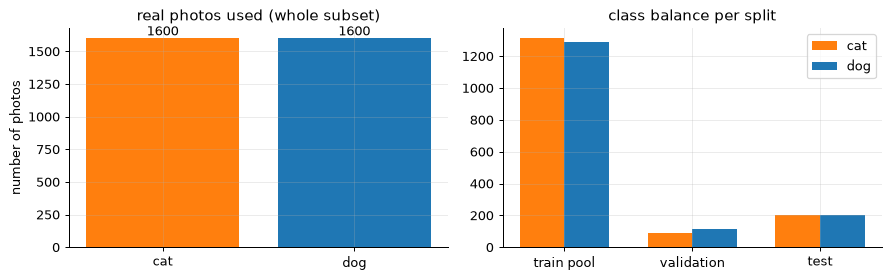

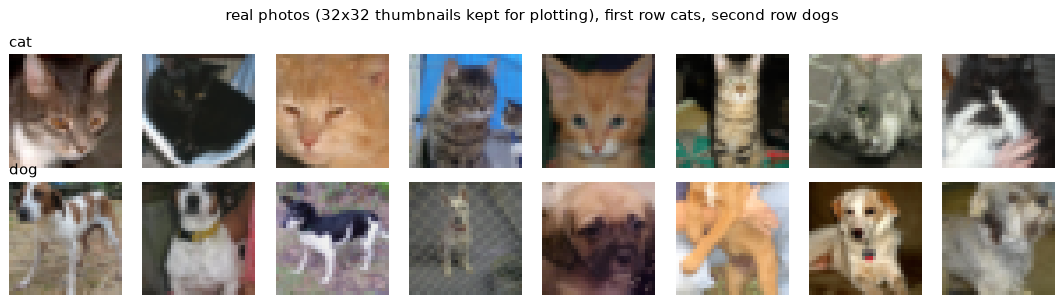

In [6]:
print("DATASET: microsoft/cats_vs_dogs (Hugging Face), 23,410 photographs in total; seeded balanced subset used here")
print("subset      :", FEATS.shape, "-> 512 VGG16 global-average-pool features per photo, image size", f"{IMG_RES}x{IMG_RES}")
print("feature names:", [f"vgg16_gap_{i}" for i in range(3)], "...", [f"vgg16_gap_{i}" for i in (509, 510, 511)], "(512 in total)")
print("original labels: 0 = cat, 1 = dog ->", {CLASS_NAMES[k]: int(c) for k, c in enumerate(np.bincount(LABELS))})
for name, yy in [("train pool", y_pool), ("validation", y_val), ("test", y_test)]:
    print(f"  {name:10s}:", {CLASS_NAMES[k]: int(c) for k, c in enumerate(np.bincount(yy.numpy(), minlength=2))})

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
b = ax[0].bar(CLASS_NAMES, np.bincount(LABELS), color=["tab:orange", "tab:blue"]); ax[0].bar_label(b)
ax[0].set_title("real photos used (whole subset)"); ax[0].set_ylabel("number of photos")
w = 0.35; xs = np.arange(3)
cnt = np.array([np.bincount(yy.numpy(), minlength=2) for yy in (y_pool, y_val, y_test)])
ax[1].bar(xs - w / 2, cnt[:, 0], w, color="tab:orange", label="cat"); ax[1].bar(xs + w / 2, cnt[:, 1], w, color="tab:blue", label="dog")
ax[1].set_xticks(xs); ax[1].set_xticklabels(["train pool", "validation", "test"]); ax[1].legend(); ax[1].set_title("class balance per split")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for r, lab in enumerate((0, 1)):
    idx = np.where(LABELS == lab)[0][:8]
    for c, i in enumerate(idx):
        ax[r, c].imshow(THUMBS[i]); ax[r, c].axis("off")
    ax[r, 0].set_title(CLASS_NAMES[lab], loc="left")
plt.suptitle("real photos (32x32 thumbnails kept for plotting), first row cats, second row dogs"); plt.tight_layout(); plt.show()

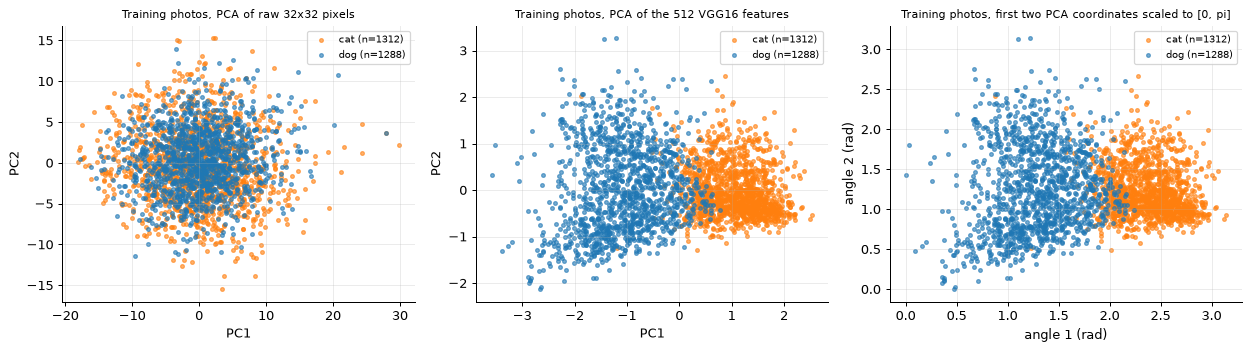

All points are real photographs with their true cat/dog label. The VGG16 map shows that the two classes are largely separable,
which is why a very small trainable head can reach a high accuracy on top of the frozen network.


In [7]:
def scatter_classes(ax, Z, y, title, xl, yl):
    for lab, col in zip((0, 1), ("tab:orange", "tab:blue")):
        m = np.asarray(y) == lab
        ax.scatter(Z[m, 0], Z[m, 1], s=9, c=col, alpha=0.6, label=f"{CLASS_NAMES[lab]} (n={m.sum()})")
    ax.set_title(title, fontsize=9); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(fontsize=8)

pix = lambda th: th.reshape(len(th), -1).astype(np.float64) / 255.0
pca_pix = PCA(n_components=2, random_state=SEED).fit(pix(THUMB_POOL))                 # fitted on the training pool only
pca_vgg = PCA(n_components=2, random_state=SEED).fit(X_pool.numpy())                  # fitted on the training pool only
Zp, Zv = pca_vgg.transform(X_pool.numpy()), pca_vgg.transform(X_test.numpy())
lo, hi = Zp.min(0), Zp.max(0)
ang = lambda Z: np.clip((Z - lo) / (hi - lo), 0, 1) * np.pi
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
scatter_classes(ax[0], pca_pix.transform(pix(THUMB_POOL)), y_pool.numpy(), "Training photos, PCA of raw 32x32 pixels", "PC1", "PC2")
scatter_classes(ax[1], Zp, y_pool.numpy(), "Training photos, PCA of the 512 VGG16 features", "PC1", "PC2")
scatter_classes(ax[2], ang(Zp), y_pool.numpy(), "Training photos, first two PCA coordinates scaled to [0, pi]", "angle 1 (rad)", "angle 2 (rad)")
plt.tight_layout(); plt.show()
print("All points are real photographs with their true cat/dog label. The VGG16 map shows that the two classes are largely separable,")
print("which is why a very small trainable head can reach a high accuracy on top of the frozen network.")

## Quantum Circuit Architecture

The quantum part is the 4-qubit circuit of the paper's Figure 5, written as a PennyLane QNode. Its input is the 4-vector `x` produced by the trainable 512-to-4 layer. Gates (paper Fig. 5): on each qubit `RY(arctan x_i)` then `RZ(arctan x_i^2)` (encoding block E(x)); then the variational block W(phi): a ring of CNOT gates (0 to 1, 1 to 2, 2 to 3, 3 to 0, our choice because the figure shows only the control dots) followed by a general single-qubit rotation `Rot(alpha_i, beta_i, gamma_i) = RZ(gamma) RY(beta) RZ(alpha)` on every qubit, which has 3 trainable parameters per qubit. The measurement is the Pauli-Z expectation of qubits 0 and 1, the two class scores. The drawing below is the **QNode that is actually evaluated** for the equivalence checks (and for the final test predictions of the trained model).

Training needs one gradient per photo for tens of thousands of steps, so the training loops use a small exact state-vector simulator of the **same gate list** written in PyTorch (product-state encoding, a basis permutation for the CNOT ring, the four rotations as one Kronecker product). The cell after the drawing asserts that this simulator and the PennyLane QNode agree to machine precision.

In [8]:
# ---------------------------------------------------------------- the 4-qubit circuit as a PennyLane QNode (the reference)
import pennylane as qml
import torch

N_Q = 4                                                   # qubits (paper Fig. 5)
dev_pl = qml.device("default.qubit", wires=N_Q)

@qml.qnode(dev_pl, interface="torch", diff_method="backprop")
def qnode(x, w):
    # x: 4 numbers (output of the classical pre-layer), w: (VQC_DEPTH, 4, 3) trainable Euler angles
    for i in range(N_Q):                                  # encoding block E(x): Ry(arctan x_i) then Rz(arctan x_i^2)
        qml.RY(torch.atan(x[i]), wires=i)
        qml.RZ(torch.atan(x[i] ** 2), wires=i)
    for d in range(w.shape[0]):                           # variational block W(phi)
        for i in range(N_Q):                              # CHOICE: ring of CNOTs 0->1->2->3->0
            qml.CNOT(wires=[i, (i + 1) % N_Q])
        for i in range(N_Q):                              # general single-qubit unitary R(alpha, beta, gamma)
            qml.Rot(w[d, i, 0], w[d, i, 1], w[d, i, 2], wires=i)
    return qml.expval(qml.PauliZ(0)), qml.expval(qml.PauliZ(1))     # Pauli-Z of the first two qubits -> two class scores

# ---------------------------------------------------------------- exact batched state-vector simulator of the same gate list
# Written in torch with an explicit batch axis so that DP-SGD can obtain per-sample gradients cheaply.
# It applies exactly the gates of the QNode above (RY, RZ, CNOT ring, Rot) to a 2^4 state vector, and a later cell
# asserts that it returns the same expectation values as the QNode.
def _cnot_ring_perm():
    # basis-state permutation implemented by CNOT(0,1) CNOT(1,2) CNOT(2,3) CNOT(3,0) applied in this order
    perm = torch.arange(16)
    def bits(k): return [(k >> (3 - q)) & 1 for q in range(4)]          # wire 0 = most significant bit
    def idx(b): return sum(bit << (3 - q) for q, bit in enumerate(b))
    out = []
    for k in range(16):
        b = bits(k)
        for c, t in [(0, 1), (1, 2), (2, 3), (3, 0)]:
            if b[c] == 1:
                b[t] ^= 1
        out.append(idx(b))
    return torch.tensor(out)                                             # image of basis state k

_PERM = _cnot_ring_perm()
_INV = torch.empty(16, dtype=torch.long); _INV[_PERM] = torch.arange(16)  # psi_new[_PERM[k]] = psi[k]  -> psi_new = psi[:, _INV]

def _rot_mats(a, b, g):
    # qml.Rot(a, b, g) = RZ(g) RY(b) RZ(a) for batched angles (B,) -> (B,2,2) complex
    c, s = torch.cos(b / 2), torch.sin(b / 2)
    j = torch.tensor(1j, dtype=torch.complex128)
    u00 = torch.exp(-j * (a + g) / 2) * c
    u01 = -torch.exp(j * (a - g) / 2) * s
    u10 = torch.exp(-j * (a - g) / 2) * s
    u11 = torch.exp(j * (a + g) / 2) * c
    return torch.stack([torch.stack([u00, u01], -1), torch.stack([u10, u11], -1)], -2)

def sim_batch(x, w):
    """x: (B,4) pre-layer outputs, w: (B,D,4,3) or (D,4,3) trainable angles -> (B,2) = (<Z0>, <Z1>) as float64.
       Encoding: every qubit starts in |0>, gets RY(arctan x_i) then RZ(arctan x_i^2); the four single-qubit states are
       combined into the 16-amplitude product state.  Variational block: CNOT ring (a basis permutation) followed by the
       four Rot gates, applied as one Kronecker product (the four Rot gates act on different wires and commute)."""
    x = x.to(torch.float64); w = w.to(torch.float64)
    B = x.shape[0]
    if w.dim() == 3:
        w = w.unsqueeze(0).expand(B, *w.shape)
    zero = torch.zeros_like(x)
    ry = _rot_mats(zero.reshape(-1), torch.atan(x).reshape(-1), zero.reshape(-1))            # RY(theta) = Rot(0, theta, 0)
    rz = _rot_mats(torch.atan(x ** 2).reshape(-1), zero.reshape(-1), zero.reshape(-1))      # RZ(phi)   = Rot(phi, 0, 0)
    q1 = (rz @ ry)[:, :, 0].reshape(B, N_Q, 2)                                               # (RZ RY |0>) for every qubit
    psi = torch.einsum("bi,bj,bk,bl->bijkl", q1[:, 0], q1[:, 1], q1[:, 2], q1[:, 3]).reshape(B, 16)
    for d in range(w.shape[1]):
        psi = psi[:, _INV]                                                                   # CNOT ring
        R = _rot_mats(w[:, d, :, 0].reshape(-1), w[:, d, :, 1].reshape(-1), w[:, d, :, 2].reshape(-1)).reshape(B, N_Q, 2, 2)
        K = torch.einsum("bxy,bzu,bvt,bsr->bxzvsyutr", R[:, 0], R[:, 1], R[:, 2], R[:, 3]).reshape(B, 16, 16)
        psi = torch.einsum("bij,bj->bi", K, psi)
    p = (psi.real ** 2 + psi.imag ** 2).reshape(B, 2, 2, 2, 2)
    z0 = p.sum(dim=(2, 3, 4))
    z1 = p.sum(dim=(1, 3, 4))
    return torch.stack([z0[:, 0] - z0[:, 1], z1[:, 0] - z1[:, 1]], dim=1)

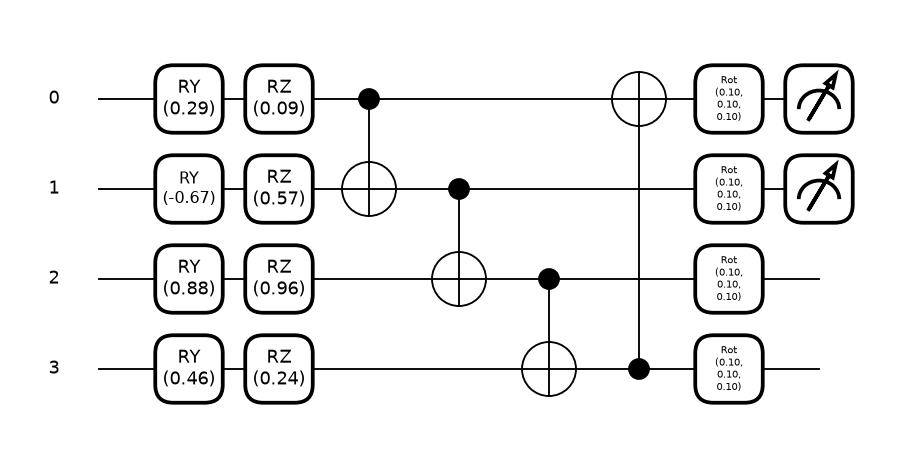

qubits                : 4
circuit depth         : 7
gate counts           : {'RY': 4, 'RZ': 4, 'CNOT': 4, 'Rot': 4}
trainable circuit parameters: 12 = 1 block x 4 qubits x 3 Euler angles
inputs to the circuit : 4 numbers (arctan-encoded), produced by the trainable Linear(512 -> 4) layer
trainable parameters of the whole hybrid head: 512*4 + 4 + 12 = 2064
measurement           : expectation of Pauli-Z on qubit 0 and qubit 1 (class scores)
ASSUMPTIONS where the paper is silent: CNOT ring 0-1-2-3-0; one variational block; wire 0 and 1 measured; Rot = RZ RY RZ.


In [9]:
x_demo = torch.tensor([0.3, -0.8, 1.2, 0.5], dtype=torch.float64)
w_demo = torch.full((VQC_DEPTH, N_Q, 3), 0.1, dtype=torch.float64)
fig, ax = qml.draw_mpl(qnode, decimals=2)(x_demo, w_demo)
plt.show()

tape = qml.workflow.construct_batch(qnode, level="top")(x_demo, w_demo)[0][0]
from collections import Counter
print("qubits                :", N_Q)
print("circuit depth         :", tape.graph.get_depth())
print("gate counts           :", dict(Counter(o.name for o in tape.operations)))
print("trainable circuit parameters:", w_demo.numel(), f"= {VQC_DEPTH} block x {N_Q} qubits x 3 Euler angles")
print("inputs to the circuit :", N_Q, "numbers (arctan-encoded), produced by the trainable Linear(512 -> 4) layer")
print("trainable parameters of the whole hybrid head: 512*4 + 4 +", w_demo.numel(), "=", 512 * 4 + 4 + w_demo.numel())
print("measurement           : expectation of Pauli-Z on qubit 0 and qubit 1 (class scores)")
print("ASSUMPTIONS where the paper is silent: CNOT ring 0-1-2-3-0; one variational block; wire 0 and 1 measured; Rot = RZ RY RZ.")

In [10]:
# ---------------------------------------------------------------- assertion: fast simulator == PennyLane QNode
g_chk = torch.Generator().manual_seed(SEED)
for depth in (1, 2):
    w_chk = torch.rand(depth, N_Q, 3, generator=g_chk, dtype=torch.float64) * 2 * math.pi - math.pi
    x_chk = torch.randn(40, N_Q, generator=g_chk, dtype=torch.float64) * 2
    sim = sim_batch(x_chk, w_chk)
    ref = torch.stack([torch.stack(qnode(x_chk[i], w_chk)) for i in range(len(x_chk))])
    err = (sim - ref).abs().max().item()
    assert err < 1e-10, err
    print(f"depth {depth}: simulator vs PennyLane QNode on 40 random inputs, max |difference| = {err:.2e}  -> OK")

depth 1: simulator vs PennyLane QNode on 40 random inputs, max |difference| = 7.77e-16  -> OK


depth 2: simulator vs PennyLane QNode on 40 random inputs, max |difference| = 5.00e-16  -> OK


## 6. The privacy accountant

DP-SGD (Abadi et al. 2016): in every step each training example is included with probability q = L/N (Poisson sampling), each per-sample gradient is clipped to L2 norm at most C, Gaussian noise of standard deviation sigma*C is added to the sum, and the sum is divided by L. The privacy cost of many such steps is tracked as a *Renyi divergence* of the sampled Gaussian mechanism (Mironov et al. 2019, closed form for integer orders), and converted to (epsilon, delta) with the moments-accountant formula epsilon = min over alpha of [ steps * RDP(alpha) + log(1/delta) / (alpha - 1) ], which is exactly the conversion of Abadi et al. The paper used the package PyVacy for this; we cannot install it from a stable index, so we implement the accountant and **verify** it three ways: against the Gaussian mechanism without sampling (closed form), against direct numerical integration of the Renyi divergence, and against the value published by Abadi et al. (q = 0.01, sigma = 4, delta = 1e-5, 10,000 steps give epsilon about 1.26).

**Worst case used here.** A client is assumed to take part in *every* round (in reality only J of K clients are drawn each round, which would only lower its epsilon; we do not claim that gain). The epsilon of a client is therefore computed for `ROUNDS * T * (N_client // L)` steps.

In [11]:
# ---------------------------------------------------------------- privacy accountant (Renyi / moments accountant)
import math
import numpy as np
from math import comb, log, exp

ALPHAS = list(range(2, 257))                               # integer Renyi orders

def _log_add(a, b):
    m = max(a, b)
    return m + math.log(math.exp(a - m) + math.exp(b - m)) if m > -math.inf else -math.inf

def rdp_sampled_gaussian(q, sigma, alpha):
    """Renyi-DP of ONE step of the Poisson-subsampled Gaussian mechanism, integer order alpha (Mironov et al. 2019):
       eps_alpha = 1/(alpha-1) * log sum_k C(alpha,k) (1-q)^(alpha-k) q^k exp((k^2-k)/(2 sigma^2))."""
    if q == 0: return 0.0
    if sigma == 0: return math.inf
    if q == 1.0: return alpha / (2 * sigma ** 2)
    logs = [math.log(comb(alpha, k)) + (alpha - k) * math.log(1 - q) + k * math.log(q) + (k * k - k) / (2 * sigma ** 2)
            for k in range(alpha + 1)]
    tot = logs[0]
    for v in logs[1:]:
        tot = _log_add(tot, v)
    return tot / (alpha - 1)

def epsilon_from_rdp(q, sigma, steps, delta, alphas=ALPHAS):
    """(eps, delta) after `steps` compositions: eps = min_alpha [ steps*rdp(alpha) + log(1/delta)/(alpha-1) ]
       (this is exactly the moments-accountant conversion of Abadi et al. 2016, lambda = alpha - 1)."""
    if sigma <= 0: return math.inf
    best = math.inf
    for a in alphas:
        e = steps * rdp_sampled_gaussian(q, sigma, a) + math.log(1 / delta) / (a - 1)
        best = min(best, e)
    return best

def calibrate_sigma(q, steps, delta, eps_target, lo=0.05, hi=60.0):
    """smallest noise multiplier that gives eps <= eps_target (bisection; eps decreases when sigma grows)."""
    for _ in range(60):
        mid = (lo + hi) / 2
        if epsilon_from_rdp(q, mid, steps, delta) > eps_target: lo = mid
        else: hi = mid
    return hi

In [12]:
from scipy import integrate

# check 1: no subsampling (q = 1) is the plain Gaussian mechanism, RDP = alpha / (2 sigma^2)
assert abs(rdp_sampled_gaussian(1.0, 2.0, 5) - 5 / (2 * 2.0 ** 2)) < 1e-12
# check 2: closed-form sum equals numerical integration of D_alpha( (1-q) N(0,s^2) + q N(1,s^2)  ||  N(0,s^2) )
def rdp_numeric(q, s, a):
    f = lambda x: math.exp(-x * x / (2 * s * s)) / math.sqrt(2 * math.pi * s * s) * ((1 - q) + q * math.exp((2 * x - 1) / (2 * s * s))) ** a
    v, _ = integrate.quad(f, -40 * s - 5, 40 * s + 5, limit=400, epsabs=1e-14, epsrel=1e-12)
    return math.log(v) / (a - 1)
for q_, s_, a_ in [(0.1, 1.0, 4), (0.1, 1.0, 8), (0.05, 2.0, 16), (0.3, 0.8, 3)]:
    d = abs(rdp_sampled_gaussian(q_, s_, a_) - rdp_numeric(q_, s_, a_))
    assert d < 1e-9, d
print("RDP closed form == numerical integration for 4 settings (max difference below 1e-9)")
# check 3: the value published by Abadi et al. (2016): q=0.01, sigma=4, delta=1e-5, 10,000 steps -> epsilon about 1.26
e_abadi = epsilon_from_rdp(0.01, 4.0, 10000, 1e-5)
assert abs(e_abadi - 1.26) < 0.02, e_abadi
print(f"Abadi et al. example: epsilon = {e_abadi:.3f} (published about 1.26)  -> OK")

def n_dp_steps(n_c, L, T, R):
    return R * T * max(1, n_c // L)

def sigma_for(eps, n_c, T, R=None):
    R = ROUNDS if R is None else R
    L = batch_size_for(n_c)
    return calibrate_sigma(L / n_c, n_dp_steps(n_c, L, T, R), DELTA, eps)

def eps_for(sigma, n_c, T, R=None):
    R = ROUNDS if R is None else R
    L = batch_size_for(n_c)
    return epsilon_from_rdp(L / n_c, sigma, n_dp_steps(n_c, L, T, R), DELTA)

rows = [{"local epochs T": T, "DP steps per client": n_dp_steps(N_C, L_BATCH, T, ROUNDS), "sigma for eps=1.24": sigma_for(EPS_TARGET, N_C, T)} for T in T_LIST]
df_sig = pd.DataFrame(rows).set_index("local epochs T")
df_sig["check eps"] = [eps_for(df_sig.loc[T, "sigma for eps=1.24"], N_C, T) for T in T_LIST]
display(df_sig.round(3))

RDP closed form == numerical integration for 4 settings (max difference below 1e-9)


Abadi et al. example: epsilon = 1.259 (published about 1.26)  -> OK


,DP steps per client,sigma for eps=1.24,check eps
local epochs T,,,
1,120,4.590,1.24
2,240,6.324,1.24
4,480,8.822,1.24


## 7. Federated DP-SGD training code

The next cell holds everything that trains a model:

* three model types sharing the same frozen-VGG inputs: `quantum` (Linear 512-4, then the circuit), `bottleneck` (the same Linear 512-4 followed by a classical 4-2 network with tanh, the same width, no circuit) and `linear` (logistic regression, 512-2);
* per-sample gradients. For the quantum model they come from one backward pass through the batched simulator with one copy of the circuit parameters per sample (so each sample's loss touches only its own copy), which gives exact per-sample gradients without a loop; the gradient of the 512-to-4 layer is then the outer product of the circuit-input gradient and the features;
* `local_train`: DP-SGD (Poisson sampling, clipping to `C`, noise `sigma*C` on the sum, divide by `L`) or, with `C = None`, ordinary shuffled mini-batch SGD;
* `federated_run`: Algorithm 1 (FedAvg): draw J clients, local training from the global model, average the parameters, evaluate the global model on the test set each round.

In [13]:
# ---------------------------------------------------------------- models, per-sample gradients, DP-SGD client update, FedAvg
import torch.nn.functional as Fnn
from torch.func import vmap, grad as tgrad

def init_params(kind, g):
    """g: torch.Generator. All parameters are float64 tensors in a dict (the 'model')."""
    u = lambda *s: (torch.rand(*s, generator=g, dtype=torch.float64) * 2 - 1)
    if kind == "quantum":            # classical pre-layer 512 -> 4 followed by the 4-qubit VQC (VQC_DEPTH blocks)
        return {"W": u(N_Q, 512) / 512 ** 0.5 * PRE_INIT, "b": torch.zeros(N_Q, dtype=torch.float64),
                "q": u(VQC_DEPTH, N_Q, 3) * np.pi}                 # CHOICE: trainable angles ~ U(-pi, pi)
    if kind == "bottleneck":         # same pre-layer, classical 4 -> 2 head instead of the circuit (matched size)
        return {"W": u(N_Q, 512) / 512 ** 0.5 * PRE_INIT, "b": torch.zeros(N_Q, dtype=torch.float64),
                "V": u(2, N_Q) / 2.0, "c": torch.zeros(2, dtype=torch.float64)}
    if kind == "linear":             # plain logistic regression on the 512 features
        return {"W": u(2, 512) / 512 ** 0.5, "b": torch.zeros(2, dtype=torch.float64)}
    raise ValueError(kind)

def n_params(p):
    return int(sum(v.numel() for v in p.values()))

def logits_fn(kind, p, Fx):
    if kind == "quantum":
        return LOGIT_SCALE * sim_batch(Fx @ p["W"].T + p["b"], p["q"])      # CHOICE: fixed temperature on the two <Z> scores
    if kind == "bottleneck":
        return torch.tanh(Fx @ p["W"].T + p["b"]) @ p["V"].T + p["c"]
    return Fx @ p["W"].T + p["b"]

def per_sample_grads(kind, p, Fx, y):
    """dict name -> (B, *shape): gradient of the cross-entropy of EACH sample separately."""
    B = Fx.shape[0]
    if kind == "quantum":
        # chain rule through the pre-layer: only dL/dx (4 numbers) and dL/dq per sample are needed from the circuit.
        x = (Fx @ p["W"].T + p["b"]).detach().requires_grad_(True)
        qb = p["q"].detach().unsqueeze(0).expand(B, *p["q"].shape).clone().requires_grad_(True)   # one copy per sample
        z = LOGIT_SCALE * sim_batch(x, qb)
        loss = Fnn.cross_entropy(z, y, reduction="sum")                 # sum of independent per-sample losses
        gx, gq = torch.autograd.grad(loss, [x, qb])
        return {"W": gx[:, :, None] * Fx[:, None, :], "b": gx, "q": gq}
    def one(pp, f, yy):
        return Fnn.cross_entropy(logits_fn(kind, pp, f[None]), yy[None])
    return vmap(tgrad(one), in_dims=(None, 0, 0))({k: v.detach() for k, v in p.items()}, Fx, y)

def batch_mean_grad(kind, p, Fx, y):
    pp = {k: v.detach().clone().requires_grad_(True) for k, v in p.items()}
    loss = Fnn.cross_entropy(logits_fn(kind, pp, Fx), y)
    gs = torch.autograd.grad(loss, list(pp.values()))
    return dict(zip(pp.keys(), gs))

def local_train(kind, p0, Fc, yc, epochs, L, lr, C, sigma, gen):
    """One client: `epochs` passes over its data.  DP mode (C is not None): Poisson sampling with rate q = L/N, per-sample
       clipping to norm C, Gaussian noise N(0, sigma^2 C^2) added to the SUM of clipped gradients, division by L (DP-SGD of
       Abadi et al.).  Non-DP mode: ordinary shuffled mini-batch SGD with batches of L."""
    p = {k: v.clone() for k, v in p0.items()}
    N = Fc.shape[0]
    steps = epochs * max(1, N // L)
    for _ in range(steps):
        if C is None:
            idx = torch.randperm(N, generator=gen)[:L]
            g = batch_mean_grad(kind, p, Fc[idx], yc[idx])
        else:
            mask = torch.rand(N, generator=gen) < (L / N)                 # Poisson sampling
            idx = torch.nonzero(mask).flatten()
            gsum = {k: torch.zeros_like(v) for k, v in p.items()}
            if len(idx) > 0:
                ps = per_sample_grads(kind, p, Fc[idx], yc[idx])
                norms = torch.sqrt(sum((v.reshape(len(idx), -1) ** 2).sum(1) for v in ps.values()))
                scale = (C / (norms + 1e-12)).clamp(max=1.0)              # clip to L2 norm <= C
                for k, v in ps.items():
                    gsum[k] = (v * scale.reshape(-1, *([1] * (v.dim() - 1)))).sum(0)
            g = {k: (gsum[k] + sigma * C * torch.randn(gsum[k].shape, generator=gen, dtype=torch.float64)) / L
                 for k in p}
        for k in p:
            p[k] = p[k] - lr * g[k]
    return p

def evaluate(kind, p, Fx, y):
    with torch.no_grad():
        pred = logits_fn(kind, p, Fx).argmax(1)
    return float((pred == y).double().mean())

def federated_run(kind, clients, test, K_sel, T, R, L, lr, C, sigma, seed, val=None, log_every=1):
    """FedAvg (paper Algorithm 1): every round the J=K_sel selected clients start from the global model, train locally for T
       epochs and the server averages their parameters.  Returns the test-accuracy curve (one value per round) and the model."""
    gen = torch.Generator().manual_seed(seed)
    p = init_params(kind, torch.Generator().manual_seed(seed + 1000))
    K = len(clients)
    curve, vcurve = [], []
    for r in range(R):
        sel = torch.randperm(K, generator=gen)[:K_sel].tolist()          # random sample of J clients
        locs = [local_train(kind, p, clients[j][0], clients[j][1], T, L, lr, C, sigma, gen) for j in sel]
        p = {k: torch.stack([lp[k] for lp in locs]).mean(0) for k in p}   # model aggregation = parameter average
        curve.append(evaluate(kind, p, *test))
        if val is not None: vcurve.append(evaluate(kind, p, *val))
    return {"curve": np.array(curve), "val": np.array(vcurve), "params": p}

In [14]:
# ---------------------------------------------------------------- unit checks of the training code
g_t = torch.Generator().manual_seed(SEED)
p_t = init_params("quantum", g_t)
Fb = X_pool[:12]; yb = y_pool[:12]
ps = per_sample_grads("quantum", p_t, Fb, yb)
for i in (0, 7):                                              # per-sample gradient == autograd of that single sample
    pp = {k: v.clone().requires_grad_(True) for k, v in p_t.items()}
    l = Fnn.cross_entropy(logits_fn("quantum", pp, Fb[i:i + 1]), yb[i:i + 1])
    gs = torch.autograd.grad(l, list(pp.values()))
    assert all(float((a - ps[k][i]).abs().max()) < 1e-10 for a, k in zip(gs, pp)), "per-sample gradient mismatch"
print("per-sample gradients of the quantum model equal single-sample autograd (max error < 1e-10) -> OK")
# DP-SGD with sigma = 0 and a huge clip norm on a full batch is plain gradient descent in expectation: check the clipped sum
nrm = torch.sqrt(sum((v.reshape(12, -1) ** 2).sum(1) for v in ps.values()))
print("per-sample gradient norms (first 6):", np.round(nrm[:6].numpy(), 3), "-> clipped to", CLIP_C)
print("parameters: quantum", n_params(init_params("quantum", g_t)), "| bottleneck", n_params(init_params("bottleneck", g_t)), "| linear", n_params(init_params("linear", g_t)))

per-sample gradients of the quantum model equal single-sample autograd (max error < 1e-10) -> OK
per-sample gradient norms (first 6): [1.213 0.797 1.524 1.698 1.908 0.66 ] -> clipped to 1.0
parameters: quantum 2064 | bottleneck 2062 | linear 1026


## 8. Classical reference points (no federation, no privacy)

For context, ordinary classifiers trained on the **same 512 scaled features** and the same training pool give the accuracy that this frozen VGG16 representation allows at this image resolution. The test set is only used for the final accuracy.

In [15]:
Xtr_np, ytr_np = X_pool.numpy(), y_pool.numpy()
Xte_np, yte_np = X_test.numpy(), y_test.numpy()
refs = {"Logistic regression": LogisticRegression(max_iter=3000, random_state=SEED),
        "SVC (RBF)": SVC(kernel="rbf", C=1.0, random_state=SEED),
        "Random forest": RandomForestClassifier(n_estimators=200, random_state=SEED)}
rows = []
for name, m in refs.items():
    t0 = time.time(); m.fit(Xtr_np, ytr_np)
    rows.append({"model": name, "train acc": m.score(Xtr_np, ytr_np), "test acc": m.score(Xte_np, yte_np), "time (s)": time.time() - t0})
df_ref = pd.DataFrame(rows).set_index("model")
display(df_ref.round(4))
ACC_CLASSICAL_CENTRAL = float(df_ref.loc["Logistic regression", "test acc"])

,train acc,test acc,time (s)
model,,,
Logistic regression,0.9842,0.9825,0.7402
SVC (RBF),0.9850,0.9825,6.6061
Random forest,0.9996,0.9850,24.2975


## 9. Choosing the learning rate on the validation split

The paper does not give its learning rate. For each model type and for DP / non-DP separately we try a few learning rates for the main setting on the **validation** photos only (one seed, a shortened run) and keep the best. The noise multiplier here is the one that gives epsilon = 1.24 for the main number of local epochs.

In [16]:
R_TUNE = max(4, ROUNDS // 2)
SIGMA_MAIN = sigma_for(EPS_TARGET, N_C, T_MAIN)
KINDS = ["quantum", "bottleneck", "linear"]
LR_BEST = {}
rows = []
t_tune = time.time()
for kind in KINDS:
    for dp in (True, False):
        best = None
        for lr in LR_GRID:
            r = federated_run(kind, CLIENTS, (X_val, y_val), J_SELECT, T_MAIN, R_TUNE, L_BATCH, lr,
                              CLIP_C if dp else None, SIGMA_MAIN if dp else 0.0, seed=SEED + 777)
            score = float(r["curve"][-2:].mean())
            rows.append({"model": kind, "DP": dp, "lr": lr, "validation acc (last 2 rounds)": score})
            if best is None or score > best[1]:
                best = (lr, score)
        LR_BEST[(kind, dp)] = best[0]
display(pd.DataFrame(rows).round(4))
print("chosen learning rates:", {f"{k[0]}{'-DP' if k[1] else ''}": v for k, v in LR_BEST.items()}, f"| tuning took {time.time()-t_tune:.0f}s")

,model,DP,lr,validation acc (last 2 rounds)
0,quantum,True,0.03,0.7400
1,quantum,True,0.10,0.8475
2,quantum,True,0.30,0.7200
3,quantum,True,1.00,0.4400
4,quantum,False,0.03,0.9300
5,quantum,False,0.10,0.9475
6,quantum,False,0.30,0.9625
7,quantum,False,1.00,0.9675
8,bottleneck,True,0.03,0.8950
9,bottleneck,True,0.10,0.9650


chosen learning rates: {'quantum-DP': 0.1, 'quantum': 1.0, 'bottleneck-DP': 0.1, 'bottleneck': 0.1, 'linear-DP': 0.1, 'linear': 0.03} | tuning took 301s


## 10. Experiment A: local epochs 1, 2, 4 with and without DP (paper Figure 6)

For each number of local epochs T the quantum model is trained federated, once without DP and once with DP at epsilon = 1.24 (the noise multiplier is calibrated for each T so the accountant reports 1.24 after the last round), over several seeds. The curves show the test accuracy of the global model after each round (mean and standard deviation over seeds). The classical `bottleneck` and `linear` models use exactly the same mechanism and inputs.

T=1: sigma=4.59, epsilon=1.240 | quantum DP final acc 0.958 | quantum non-DP 0.983 | 337s elapsed


T=2: sigma=6.32, epsilon=1.240 | quantum DP final acc 0.934 | quantum non-DP 0.984 | 1050s elapsed


T=4: sigma=8.82, epsilon=1.240 | quantum DP final acc 0.924 | quantum non-DP 0.987 | 2364s elapsed


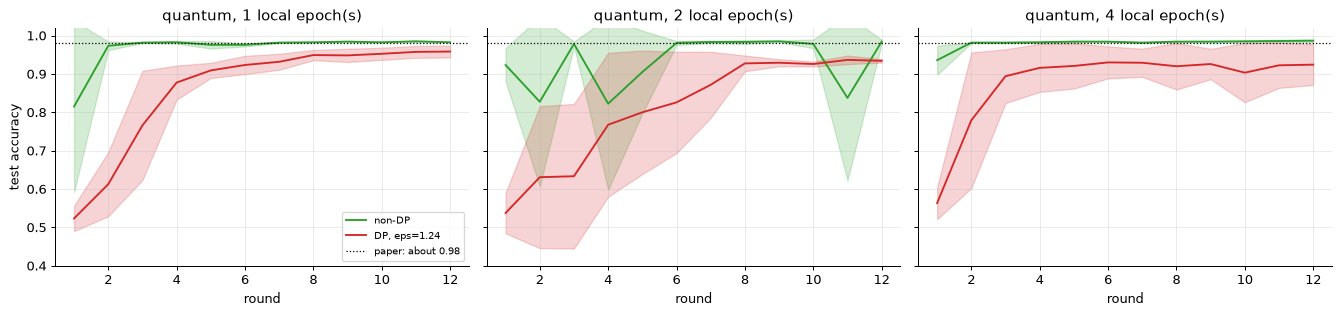

In [17]:
RES = {}                    # (kind, dp, T, sigma) -> array (seeds, rounds)
FINAL_PARAMS = {}
def run_many(kind, dp, T, sigma, n_seeds, clients=None, J=None, rounds=None, tag=""):
    clients = CLIENTS if clients is None else clients
    J = J_SELECT if J is None else J
    rounds = ROUNDS if rounds is None else rounds
    n_c = len(clients[0][1]); L = batch_size_for(n_c)
    key = (kind, dp, T, round(float(sigma), 4), len(clients), n_seeds, rounds, tag)
    if key in RES: return RES[key]
    curves = []
    for s in range(n_seeds):
        r = federated_run(kind, clients, (X_test, y_test), J, T, rounds, L, LR_BEST[(kind, dp)],
                          CLIP_C if dp else None, float(sigma) if dp else 0.0, seed=SEED + 100 * s + T)
        curves.append(r["curve"]); FINAL_PARAMS[(kind, dp, T, len(clients), s, tag)] = r["params"]
    RES[key] = np.array(curves)
    return RES[key]

t_expA = time.time()
EXPA = {}
for T in T_LIST:
    sig = sigma_for(EPS_TARGET, N_C, T)
    for kind in KINDS:
        EXPA[(kind, False, T)] = run_many(kind, False, T, 0.0, N_SEEDS)
        EXPA[(kind, True, T)] = run_many(kind, True, T, sig, N_SEEDS)
    print(f"T={T}: sigma={sig:.2f}, epsilon={eps_for(sig, N_C, T):.3f} | quantum DP final acc {EXPA[('quantum', True, T)][:, -1].mean():.3f}"
          f" | quantum non-DP {EXPA[('quantum', False, T)][:, -1].mean():.3f} | {time.time()-t_expA:.0f}s elapsed")

fig, axes = plt.subplots(1, len(T_LIST), figsize=(5 * len(T_LIST), 3.6), sharey=True)
axes = np.atleast_1d(axes)
rr = np.arange(1, ROUNDS + 1)
for ax, T in zip(axes, T_LIST):
    for dp, col, lab in [(False, "tab:green", "non-DP"), (True, "tab:red", f"DP, eps={EPS_TARGET}")]:
        c = EXPA[("quantum", dp, T)]
        ax.plot(rr, c.mean(0), color=col, label=lab); ax.fill_between(rr, c.mean(0) - c.std(0), c.mean(0) + c.std(0), color=col, alpha=0.2)
    ax.axhline(0.98, color="k", ls=":", lw=1, label="paper: about 0.98")
    ax.set_title(f"quantum, {T} local epoch(s)"); ax.set_xlabel("round"); ax.set_ylim(0.4, 1.02)
axes[0].set_ylabel("test accuracy"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

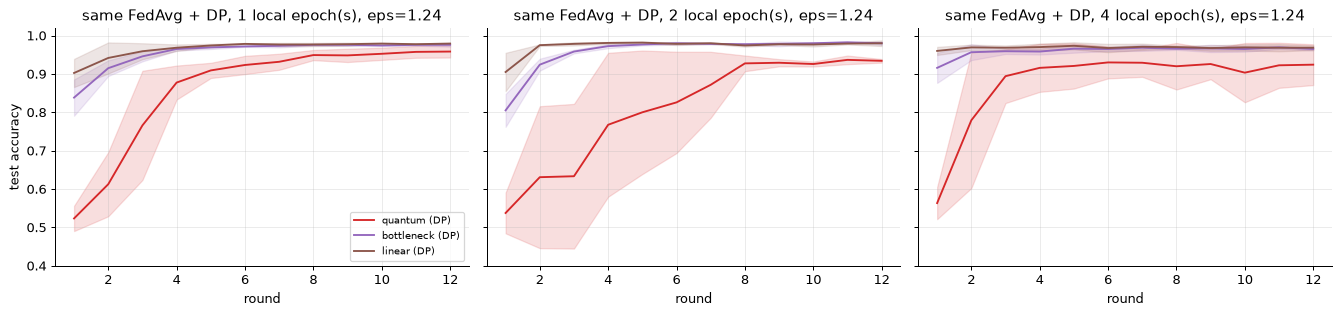

,model,DP,T,final test acc (mean),std over seeds,last-3-rounds acc
0,quantum,False,1,0.9825,0.0000,0.9833
1,quantum,True,1,0.9583,0.0156,0.9561
2,bottleneck,False,1,0.9792,0.0012,0.9794
3,bottleneck,True,1,0.9758,0.0047,0.9753
4,linear,False,1,0.9850,0.0020,0.9853
5,linear,True,1,0.9792,0.0012,0.9786
6,quantum,False,2,0.9842,0.0051,0.9333
7,quantum,True,2,0.9342,0.0047,0.9322
8,bottleneck,False,2,0.9800,0.0020,0.9800
9,bottleneck,True,2,0.9800,0.0041,0.9808


In [18]:
fig, axes = plt.subplots(1, len(T_LIST), figsize=(5 * len(T_LIST), 3.6), sharey=True)
axes = np.atleast_1d(axes)
for ax, T in zip(axes, T_LIST):
    for kind, col in [("quantum", "tab:red"), ("bottleneck", "tab:purple"), ("linear", "tab:brown")]:
        c = EXPA[(kind, True, T)]
        ax.plot(rr, c.mean(0), color=col, label=f"{kind} (DP)"); ax.fill_between(rr, c.mean(0) - c.std(0), c.mean(0) + c.std(0), color=col, alpha=0.15)
    ax.set_title(f"same FedAvg + DP, {T} local epoch(s), eps={EPS_TARGET}"); ax.set_xlabel("round"); ax.set_ylim(0.4, 1.02)
axes[0].set_ylabel("test accuracy"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

rows = []
for T in T_LIST:
    for kind in KINDS:
        for dp in (False, True):
            c = EXPA[(kind, dp, T)]
            rows.append({"model": kind, "DP": dp, "T": T, "final test acc (mean)": c[:, -1].mean(), "std over seeds": c[:, -1].std(),
                         "last-3-rounds acc": c[:, -3:].mean()})
df_A = pd.DataFrame(rows)
display(df_A.round(4))

### Central (non-federated) quantum training for comparison

The paper says federated accuracy approaches that of non-federated training. As the non-federated reference we train the same quantum model on all training photos at one site (one client, no DP) for the same number of rounds, each round being `T_MAIN` epochs.

In [19]:
CENTRAL = make_clients(1)
c_central = run_many("quantum", False, T_MAIN, 0.0, N_SEEDS_SWEEP, clients=CENTRAL, J=1, tag="central")
print("central quantum, final test accuracy per seed:", np.round(c_central[:, -1], 4))

central quantum, final test accuracy per seed: [0.985 0.985]


## 11. Experiment B: three noise multipliers (paper Figure 7), and accuracy versus epsilon

The paper trains with sigma = 0.15, 1 and 4. The epsilon of each setting follows from the accountant (a very small sigma gives an enormous epsilon, i.e. essentially no privacy). Then the study is repeated the other way round: for a list of target epsilons the noise multiplier is calibrated, and the accuracy is recorded, for the quantum model and the two classical models.

,epsilon (delta=1e-5),final test acc,last-3-rounds acc
sigma,,,
0.15,9572.9387,0.9825,0.9825
1.00,13.3674,0.9800,0.9788
4.00,2.0343,0.9662,0.9612


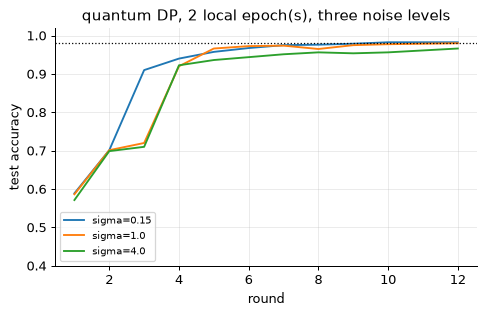

485s


In [20]:
t_expB = time.time()
rows = []
EXPB = {}
for sg in SIGMAS_PAPER:
    ep = eps_for(sg, N_C, T_MAIN)
    c = run_many("quantum", True, T_MAIN, sg, N_SEEDS_SWEEP, tag="sigmaB")
    EXPB[sg] = c
    rows.append({"sigma": sg, "epsilon (delta=1e-5)": ep, "final test acc": c[:, -1].mean(), "last-3-rounds acc": c[:, -3:].mean()})
df_B = pd.DataFrame(rows).set_index("sigma")
display(df_B.round(4))
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for sg, col in zip(SIGMAS_PAPER, ("tab:blue", "tab:orange", "tab:green")):
    c = EXPB[sg]; ax.plot(rr, c.mean(0), color=col, label=f"sigma={sg}")
ax.axhline(0.98, color="k", ls=":", lw=1); ax.set_xlabel("round"); ax.set_ylabel("test accuracy"); ax.set_ylim(0.4, 1.02)
ax.set_title(f"quantum DP, {T_MAIN} local epoch(s), three noise levels"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"{time.time()-t_expB:.0f}s")

,target epsilon,sigma,model,final test acc,last-3-rounds acc
0,0.50,15.1797,quantum,0.7612,0.7667
1,0.50,15.1797,bottleneck,0.9412,0.9442
2,0.50,15.1797,linear,0.9625,0.9600
3,1.24,6.3242,quantum,0.9375,0.9367
4,1.24,6.3242,bottleneck,0.9800,0.9808
5,1.24,6.3242,linear,0.9838,0.9812
6,3.00,2.8411,quantum,0.9738,0.9700
7,3.00,2.8411,bottleneck,0.9775,0.9792
8,3.00,2.8411,linear,0.9812,0.9817
9,8.00,1.3483,quantum,0.9775,0.9779


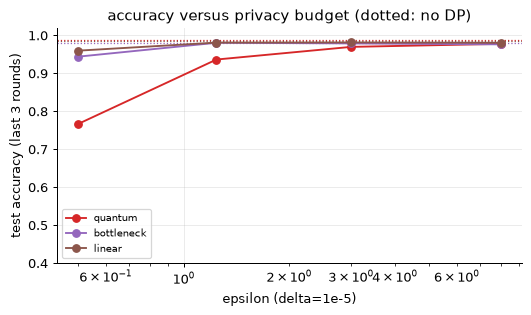

1324s


In [21]:
t_expE = time.time()
rows = []
for ep_t in EPS_LIST:
    sg = sigma_for(ep_t, N_C, T_MAIN)
    for kind in KINDS:
        c = run_many(kind, True, T_MAIN, sg, N_SEEDS_SWEEP, tag="epsE")
        rows.append({"target epsilon": ep_t, "sigma": sg, "model": kind, "final test acc": c[:, -1].mean(), "last-3-rounds acc": c[:, -3:].mean()})
for kind in KINDS:
    c = run_many(kind, False, T_MAIN, 0.0, N_SEEDS_SWEEP, tag="epsE")
    rows.append({"target epsilon": np.inf, "sigma": 0.0, "model": kind, "final test acc": c[:, -1].mean(), "last-3-rounds acc": c[:, -3:].mean()})
df_E = pd.DataFrame(rows)
display(df_E.round(4))
fig, ax = plt.subplots(figsize=(6, 3.6))
for kind, col in [("quantum", "tab:red"), ("bottleneck", "tab:purple"), ("linear", "tab:brown")]:
    d = df_E[(df_E.model == kind)].copy()
    fin = d[np.isfinite(d["target epsilon"])]
    ax.plot(fin["target epsilon"], fin["last-3-rounds acc"], "o-", color=col, label=kind)
    ax.axhline(float(d[~np.isfinite(d["target epsilon"])]["last-3-rounds acc"].iloc[0]), color=col, ls=":", lw=1)
ax.set_xscale("log"); ax.set_xlabel("epsilon (delta=1e-5)"); ax.set_ylabel("test accuracy (last 3 rounds)"); ax.set_ylim(0.4, 1.02)
ax.set_title("accuracy versus privacy budget (dotted: no DP)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"{time.time()-t_expE:.0f}s")

## 12. Experiment C: accuracy versus the number of clients

The same training pool is split among more or fewer clients. With more clients every client holds fewer photos, so for the same sampling rate q the same noise multiplier gives a larger epsilon (fewer examples to hide among), and for a fixed epsilon the noise multiplier must grow. We calibrate sigma so that every setting has epsilon = 1.24 and report the accuracy, with the number of clients selected per round fixed.

,clients K,photos per client,selected J,sigma (eps=1.24),model,DP last-3 acc,non-DP last-3 acc
0,5,520,5,6.3242,quantum,0.9792,0.9862
1,5,520,5,6.3242,linear,0.9817,0.9842
2,10,260,5,6.3242,quantum,0.9367,0.9879
3,10,260,5,6.3242,linear,0.9812,0.9862
4,20,130,5,6.3242,quantum,0.8683,0.9850
5,20,130,5,6.3242,linear,0.9542,0.9867


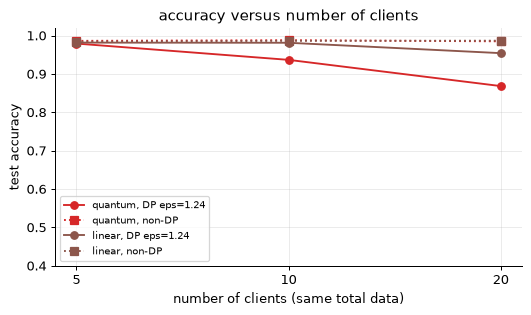

771s


In [22]:
t_expC = time.time()
rows = []
for K in K_LIST:
    cl = make_clients(K); n_c = len(cl[0][1]); Jk = min(J_SELECT, K)
    sg = sigma_for(EPS_TARGET, n_c, T_MAIN)
    for kind in ("quantum", "linear"):
        cd = run_many(kind, True, T_MAIN, sg, N_SEEDS_SWEEP, clients=cl, J=Jk, tag="clientsC")
        cn = run_many(kind, False, T_MAIN, 0.0, N_SEEDS_SWEEP, clients=cl, J=Jk, tag="clientsC")
        rows.append({"clients K": K, "photos per client": n_c, "selected J": Jk, "sigma (eps=1.24)": sg, "model": kind,
                     "DP last-3 acc": cd[:, -3:].mean(), "non-DP last-3 acc": cn[:, -3:].mean()})
df_C = pd.DataFrame(rows)
display(df_C.round(4))
fig, ax = plt.subplots(figsize=(6, 3.6))
for kind, col in [("quantum", "tab:red"), ("linear", "tab:brown")]:
    d = df_C[df_C.model == kind]
    ax.plot(d["clients K"], d["DP last-3 acc"], "o-", color=col, label=f"{kind}, DP eps=1.24")
    ax.plot(d["clients K"], d["non-DP last-3 acc"], "s:", color=col, label=f"{kind}, non-DP")
ax.set_xscale("log", base=2); ax.set_xticks(K_LIST); ax.set_xticklabels(K_LIST); ax.set_xlabel("number of clients (same total data)"); ax.set_ylabel("test accuracy")
ax.set_ylim(0.4, 1.02); ax.legend(fontsize=8); ax.set_title("accuracy versus number of clients")
plt.tight_layout(); plt.show()
print(f"{time.time()-t_expC:.0f}s")

## 13. Looking inside the trained quantum model

Here the trained DP model (main setting, first seed) is examined. First its **final predictions are recomputed with the PennyLane QNode** (not the fast simulator) and compared with the simulator, then the confusion matrix on the test photos is shown, and finally the four circuit-input angles `arctan(x_i)` that the learned 512-to-4 layer produces are plotted for the real test photos coloured by their true label (the model's own encoding, the counterpart of the PCA plots above).

trained DP model on 400 test photos: PennyLane QNode vs simulator max |difference| = 5.55e-16; accuracy via the QNode = 0.9375


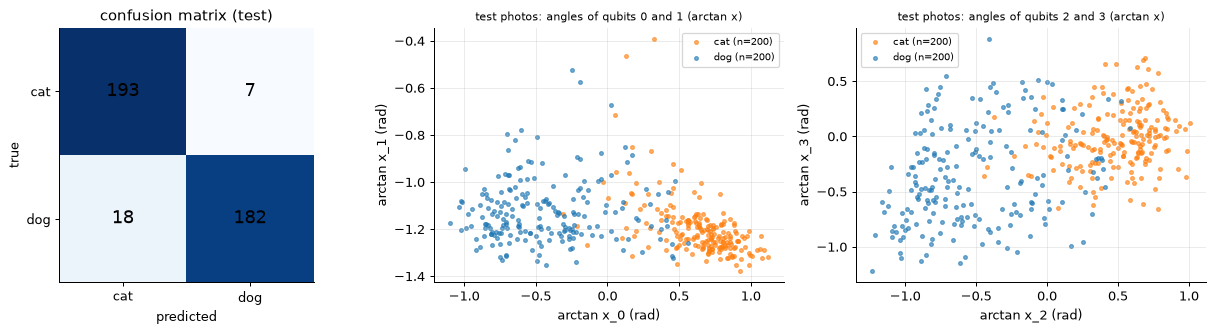

per-class precision (cat, dog): [0.915 0.963] | recall: [0.965 0.91 ] | F1: [0.939 0.936]


In [23]:
p_fin = FINAL_PARAMS[("quantum", True, T_MAIN, K_CLIENTS, 0, "")]
with torch.no_grad():
    x_in = X_test @ p_fin["W"].T + p_fin["b"]
    z_sim = sim_batch(x_in, p_fin["q"])
    z_qn = torch.stack([torch.stack(qnode(x_in[i], p_fin["q"])) for i in range(len(x_in))])
err = (z_sim - z_qn).abs().max().item()
assert err < 1e-10, err
pred = (LOGIT_SCALE * z_qn).argmax(1)
acc_qnode = float((pred == y_test).double().mean())
print(f"trained DP model on {len(y_test)} test photos: PennyLane QNode vs simulator max |difference| = {err:.2e}; accuracy via the QNode = {acc_qnode:.4f}")
assert abs(acc_qnode - evaluate("quantum", p_fin, X_test, y_test)) < 1e-12

cm = confusion_matrix(y_test.numpy(), pred.numpy(), labels=[0, 1])
pr, rc, f1, _ = precision_recall_fscore_support(y_test.numpy(), pred.numpy(), labels=[0, 1], zero_division=0)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].imshow(cm, cmap="Blues"); ax[0].set_xticks([0, 1]); ax[0].set_yticks([0, 1]); ax[0].set_xticklabels(CLASS_NAMES); ax[0].set_yticklabels(CLASS_NAMES)
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, int(cm[i, j]), ha="center", va="center", color="black", fontsize=14)
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true"); ax[0].set_title("confusion matrix (test)"); ax[0].grid(False)
angles = torch.atan(x_in).numpy()
scatter_classes(ax[1], angles[:, :2], y_test.numpy(), "test photos: angles of qubits 0 and 1 (arctan x)", "arctan x_0 (rad)", "arctan x_1 (rad)")
scatter_classes(ax[2], angles[:, 2:], y_test.numpy(), "test photos: angles of qubits 2 and 3 (arctan x)", "arctan x_2 (rad)", "arctan x_3 (rad)")
plt.tight_layout(); plt.show()
print("per-class precision (cat, dog):", np.round(pr, 3), "| recall:", np.round(rc, 3), "| F1:", np.round(f1, 3))

## 14. Side by side with the paper

Verdict rule (from the project brief): an accuracy claim is "reproduced" if the notebook is within 2 accuracy points of the paper's value (or on the right side of an inequality), "not reached" if lower by more, "exceeded" if higher by more, and "cannot be checked" if the paper gives no usable number. Accuracies are means over seeds of the last three rounds.

In [24]:
REACH = 0.90                                  # "converged" = mean test accuracy over seeds first reaches this value
def rounds_to_converge(curve_mean, thr=REACH):
    idx = np.where(curve_mean >= thr)[0]
    return int(idx[0]) + 1 if len(idx) else ROUNDS + 1          # ROUNDS + 1 means "never reached within the budget"

def spread(curves):                          # average over rounds of the std across seeds, plus round-to-round std in the last half
    return float(curves.std(0).mean()), float(np.mean([c[len(c) // 2:].std() for c in curves]))

def verdict(value, target, tol=0.02):
    if value >= target - tol and value <= target + tol: return "reproduced"
    return "exceeded" if value > target + tol else f"not reached (gap {target - value:+.3f})"

rows = []
accs_dp = {T: EXPA[("quantum", True, T)][:, -3:].mean() for T in T_LIST}
accs_nd = {T: EXPA[("quantum", False, T)][:, -3:].mean() for T in T_LIST}
eps_used = {T: eps_for(sigma_for(EPS_TARGET, N_C, T), N_C, T) for T in T_LIST}
for T in T_LIST:
    rows.append({"claim": f"QFL-DP accuracy, T={T} local epochs, eps={eps_used[T]:.2f}", "paper": "about 0.98 (Fig. 6)", "this notebook": f"{accs_dp[T]:.3f}", "verdict": verdict(accs_dp[T], 0.98)})
rows.append({"claim": "non-DP QFL accuracy (mean over T)", "paper": "about 0.98 (Fig. 6)", "this notebook": f"{np.mean(list(accs_nd.values())):.3f}", "verdict": verdict(np.mean(list(accs_nd.values())), 0.98)})
rows.append({"claim": "privacy cost below 1.3", "paper": "eps < 1.3 (abstract)", "this notebook": f"max eps = {max(eps_used.values()):.3f} (sigma calibrated; accountant verified)",
             "verdict": "reproduced (by calibration)" if max(eps_used.values()) < 1.3 else "not reached"})
c_fed = EXPA[("quantum", False, T_MAIN)][:, -3:].mean(); c_cen = c_central[:, -3:].mean()
rows.append({"claim": "federated ~ non-federated accuracy (no DP)", "paper": "approximately equal (Sec. 4.2)", "this notebook": f"federated {c_fed:.3f} vs central {c_cen:.3f}",
             "verdict": "reproduced" if abs(c_fed - c_cen) <= 0.02 else f"not reached (gap {c_cen - c_fed:+.3f})"})
if len(T_LIST) > 1:
    rt = {T: rounds_to_converge(EXPA[("quantum", True, T)].mean(0)) for T in T_LIST}
    sp = {T: spread(EXPA[("quantum", True, T)])[0] for T in T_LIST}
    ok_r = rt[T_LIST[-1]] < rt[T_LIST[0]] or (rt[T_LIST[-1]] == rt[T_LIST[0]] <= 2); ok_s = sp[T_LIST[-1]] <= sp[T_LIST[0]]
    never = all(v == ROUNDS + 1 for v in rt.values())
    rows.append({"claim": f"more local epochs -> fewer rounds to reach {REACH:.2f} accuracy (DP)", "paper": "observed (Fig. 6)", "this notebook": f"rounds to reach {REACH:.2f}: {rt} ({ROUNDS + 1} = never)",
                 "verdict": "cannot be checked (DP model never reaches the level)" if never else ("reproduced" if ok_r else "not reached")})
    rows.append({"claim": "more local epochs -> lower variance (DP)", "paper": "observed (Fig. 6)", "this notebook": "std over seeds " + str({k: round(v, 3) for k, v in sp.items()}),
                 "verdict": "reproduced" if ok_s else "not reached"})
T0 = T_LIST[-1]
rt_dp, rt_nd = rounds_to_converge(EXPA[("quantum", True, T0)].mean(0)), rounds_to_converge(EXPA[("quantum", False, T0)].mean(0))
sp_dp, sp_nd = spread(EXPA[("quantum", True, T0)])[1], spread(EXPA[("quantum", False, T0)])[1]
rows.append({"claim": f"DP converges slower and noisier than non-DP (T={T0})", "paper": "observed (Fig. 6)", "this notebook": f"rounds to reach {REACH:.2f}: {rt_dp} (DP) vs {rt_nd} (non-DP), {ROUNDS + 1} = never; round-to-round std {sp_dp:.3f} vs {sp_nd:.3f}",
             "verdict": "reproduced" if (rt_dp >= rt_nd and sp_dp >= sp_nd) else "not reached"})
fa = df_B["last-3-rounds acc"].values
rows.append({"claim": "final accuracy about 0.98 and equal for sigma = 0.15, 1, 4", "paper": "about 0.98, no difference (Fig. 7)",
             "this notebook": "acc " + ", ".join(f"{a:.3f}" for a in fa) + " ; eps " + ", ".join(f"{e:.3g}" for e in df_B["epsilon (delta=1e-5)"]),
             "verdict": ("reproduced" if (fa.max() - fa.min() <= 0.02 and fa.mean() >= 0.96) else ("accuracies equal but below 0.98: not reached" if fa.max() - fa.min() <= 0.02 else "not reached (accuracy depends on sigma)"))})
rows.append({"claim": "a classical federated model with the same DP (not in the paper)", "paper": "listed as future work", "this notebook":
             "linear " + f"{EXPA[('linear', True, T_MAIN)][:, -3:].mean():.3f}" + ", bottleneck " + f"{EXPA[('bottleneck', True, T_MAIN)][:, -3:].mean():.3f}" + f" vs quantum {accs_dp[T_MAIN]:.3f}", "verdict": "cannot be checked (no paper value)"})
rows.append({"claim": "quantum advantage / hardware (NISQ) suitability", "paper": "claimed qualitatively", "this notebook": "exact noiseless simulation only", "verdict": "cannot be checked"})
df_V = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 140, "display.width", 250)
display(df_V)

,claim,paper,this notebook,verdict
0,"QFL-DP accuracy, T=1 local epochs, eps=1.24",about 0.98 (Fig. 6),0.956,not reached (gap +0.024)
1,"QFL-DP accuracy, T=2 local epochs, eps=1.24",about 0.98 (Fig. 6),0.932,not reached (gap +0.048)
2,"QFL-DP accuracy, T=4 local epochs, eps=1.24",about 0.98 (Fig. 6),0.917,not reached (gap +0.063)
3,non-DP QFL accuracy (mean over T),about 0.98 (Fig. 6),0.967,reproduced
4,privacy cost below 1.3,eps < 1.3 (abstract),max eps = 1.240 (sigma calibrated; accountant verified),reproduced (by calibration)
5,federated ~ non-federated accuracy (no DP),approximately equal (Sec. 4.2),federated 0.933 vs central 0.985,not reached (gap +0.051)
6,more local epochs -> fewer rounds to reach 0.90 accuracy (DP),observed (Fig. 6),"rounds to reach 0.90: {1: 5, 2: 8, 4: 4} (13 = never)",reproduced
7,more local epochs -> lower variance (DP),observed (Fig. 6),"std over seeds {1: 0.037, 2: 0.087, 4: 0.065}",not reached
8,DP converges slower and noisier than non-DP (T=4),observed (Fig. 6),"rounds to reach 0.90: 4 (DP) vs 1 (non-DP), 13 = never; round-to-round std 0.012 vs 0.003",reproduced
9,"final accuracy about 0.98 and equal for sigma = 0.15, 1, 4","about 0.98, no difference (Fig. 7)","acc 0.983, 0.979, 0.961 ; eps 9.57e+03, 13.4, 2.03",not reached (accuracy depends on sigma)


### What the numbers above say (written after the full run; every number is from the tables and verdicts above)

* **Non-private federated quantum training reproduces the paper's level**: final-round test accuracy 0.983, 0.984 and 0.987 for 1, 2 and 4 local epochs (paper: about 0.98). The same model trained centrally on all pooled photos reaches 0.985, and logistic regression on the same 512 features reaches 0.9825. The "last-3-rounds" verdict for federated versus central (0.933 versus 0.985) is driven by a transient dip of the 2-epoch non-DP quantum run (final-round 0.984 but last-3-round mean 0.933), a sign that the learning rate of 1.0 picked on a short validation run is on the unstable side; it is not a systematic gap.
* **With DP at epsilon = 1.24 the quantum model does not reach 0.98 here**: 0.958, 0.934 and 0.924 final-round accuracy for 1, 2 and 4 local epochs (last-3-rounds 0.956, 0.932, 0.917), and the accuracy *falls* with more local epochs, because the calibrated noise multiplier grows (4.6, 6.3, 8.8) when the privacy budget is spread over more steps. Our noise is added to all 2,064 trainable parameters, most of them in the classical 512-to-4 layer. The classical models under the identical mechanism, inputs and epsilon stay at 0.97-0.98 (linear 0.979, 0.980, 0.968; bottleneck 0.976, 0.980, 0.965), so in this reproduction the quantum head is the more noise-sensitive part, not a privacy advantage.
* **Accuracy versus epsilon (T = 2)**: quantum 0.77 at epsilon 0.5, 0.94 at 1.24, 0.97 at 3, 0.98 at 8 and 0.99 without DP (last-3-rounds means); the linear model is at 0.96, 0.98, 0.98, 0.98 and 0.99. **Accuracy versus clients** (same total data, epsilon 1.24, J = 5): quantum 0.979 with 5 clients of 520 photos, 0.937 with 10 clients of 260 and 0.868 with 20 clients of 130; linear 0.982, 0.981 and 0.954; without DP everything stays near 0.985. Fewer photos per client means a larger sampling noise ratio for the same epsilon.
* **Sigma = 0.15, 1, 4 (Figure 7)**: accuracy 0.983, 0.979 and 0.961 with epsilon of about 9,600, 13 and 2.0. The paper's statement that the final accuracies do not differ holds for sigma = 0.15 and 1, but not for sigma = 4 here. Note that none of these three settings has epsilon below 1.3.
* **Rounds to converge**: rounds to reach 0.90 are 5, 8 and 4 for 1, 2 and 4 local epochs. The verdict above compares only T = 1 with T = 4 and says "reproduced"; the sequence is not monotone (T = 2 is slowest), so treat the claim as only weakly supported. The variance claim is not reached.
* **Overall**: the notebook is *partially reproduced*: the pipeline, the circuit, the accountant (verified against Abadi et al.) and the non-private accuracy of about 0.98 are reproduced; the 0.98 accuracy at epsilon = 1.24 and the insensitivity to the noise level are not reached with the choices documented in section 1 (112 px images, 3,200 photos, 10 clients, own batch size, learning rate and noise calibration).


In [25]:
print(f"Total wall-clock time of this notebook: {(time.time()-T_START)/60:.1f} min (FAST_MODE={FAST_MODE})")
print("Reminder: this run used", N_TOTAL, "of the 23,410 photos,", K_CLIENTS, "clients, image size", IMG_RES, "- see the table in section 1 for every deviation.")

Total wall-clock time of this notebook: 124.2 min (FAST_MODE=False)
Reminder: this run used 3200 of the 23,410 photos, 10 clients, image size 112 - see the table in section 1 for every deviation.


## 15. Reading the paper critically

* **The reported privacy number depends on conventions the paper does not state.** Epsilon is "global, a function of the total rounds", but not which dataset size, batch size or sampling the accountant assumed, nor whether the 5-of-100 client selection was credited. Here the conservative reading is used (every client takes part in every round). Without these, 1.24 cannot be compared across papers.
* **Sigma and epsilon are not independent knobs in the paper's Figure 7.** It lists sigma = 0.15, 1 and 4 and says "higher epsilon" gives slower training, while noise is what lowers epsilon; with sigma = 0.15 the privacy guarantee is vacuous (epsilon in the hundreds or thousands, see the table above), so "all three reach 0.98" mostly shows that the task is easy rather than that DP is free.
* **The task is easy.** A frozen ImageNet network separates cats from dogs almost linearly; the classical logistic regression above is as good as or better than the quantum head. The quantum circuit adds a 12-parameter bottleneck; nothing in the experiment shows an advantage, and the paper itself lists classical comparisons as future work.
* **Privacy of the pre-trained network and of the features.** The VGG16 is trained on ImageNet public data, so freezing it costs no privacy here, but the quantum circuit only sees a 4-number summary; the DP guarantee covers only the trainable head, and our constant `FEATURE_SCALE` is data independent on purpose (a data-dependent standardisation would leak).
* **Simulation, not hardware.** "Quantum computations are inherently secure because of no-cloning" does not apply to a simulator, and the DP guarantee is a statement about the training algorithm, not about the quantum device.
* **Small data and few repeats.** Three repeats on a few hundred test photos give accuracy differences of one or two points that are within noise.

## 16. Exercises

1. Set `IMG_RES = 224` and `N_TOTAL` as large as your machine allows. How close does the non-DP accuracy get to the paper's 0.98, and does the DP accuracy follow?
2. Change `VQC_DEPTH` to 2 or 3. Does the quantum head improve over the bottleneck network, and how does the per-sample gradient norm (and hence clipping) change?
3. Replace the CNOT ring by a chain (0-1, 1-2, 2-3) or remove the CNOTs. The assertion in the circuit section will fail until the simulator permutation `_cnot_ring_perm` is changed; fix it and compare.
4. The accountant here assumes every client participates in every round. Derive (or look up) an accountant that credits client sampling and recompute epsilon for the main setting.
5. Add the paper's `membership inference` attack idea: train with and without DP and compare the model's confidence on training photos and on test photos.